# NN_L11_pdp_ice

**Partial dependence (PDP) and individual conditional expectation (ICE) of the predicted house value on median income, MLP on California housing.**

Neural Networks and Deep Learning (NN), Lecture 11 · Daniel Traian Pele, Bucharest University of Economic Studies

[Open in Colab](https://colab.research.google.com/github/danpele/NEURAL_BIZ/blob/main/Quantlets/L11/NN_L11_pdp_ice/NN_L11_pdp_ice.ipynb)

In [1]:
import os
# course data: the local copy of the repository if there is one, else the public repository on GitHub
_LOCAL = os.path.join('..', '..', '..', 'data', 'clean')
DATA = _LOCAL + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/NEURAL_BIZ/main/data/clean/'
REPO = os.path.join('..', '..', '..') + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/NEURAL_BIZ/main/'

In [2]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')
# course chart style: transparent background, no gridlines, legend at the bottom outside the axes, four-digit years
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#222222', 'axes.labelcolor': '#222222', 'xtick.color': '#222222', 'ytick.color': '#222222',
    'text.color': '#222222', 'font.size': 11, 'axes.labelsize': 11, 'legend.fontsize': 10.5, 'legend.frameon': False,
    'lines.linewidth': 1.4, 'font.family': 'DejaVu Sans'})
SERIES = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
PAL = {'data': '#2a78d6', 'model': '#eb6834', 'benchmark': '#1baf7a', 'alt': '#eda100',
       'train': '#2a78d6', 'valid': '#eb6834', 'test': '#6250d6', 'positive': '#e34948', 'negative': '#2a78d6'}


def legend_bottom(fig, ncol=4):
    h, l_ = [], []
    for ax in fig.axes:
        for hh, ll in zip(*ax.get_legend_handles_labels()):
            if ll not in l_:
                h.append(hh); l_.append(ll)
    if h:
        fig.legend(h, l_, loc='lower center', ncol=min(ncol, len(h)), bbox_to_anchor=(0.5, 0.0), frameon=False)


def show(key, label, value):
    # print a number of the slide; [key] = its name in lectures/Lk/Lk_numbers.json
    print(f'{label} = {value}   [{key}]')

In [3]:
import torch, torch.nn as nn
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, average_precision_score
from scipy import stats
import shap
SEED = 20261108; np.random.seed(SEED); torch.manual_seed(SEED); torch.set_num_threads(4)
class MLP(nn.Module):
    def __init__(self, d, h1=64, h2=32, p=0.1):
        super().__init__()
        self.f = nn.Sequential(nn.Linear(d, h1), nn.ReLU(), nn.Dropout(p), nn.Linear(h1, h2), nn.ReLU(), nn.Dropout(p), nn.Linear(h2, 1))
    def forward(self, x): return self.f(x).squeeze(-1)
def train_mlp(seed, Xa, ya, Xv, yv, w_pos=1.0, epochs=300, patience=25, task='clf', lr=1e-3, sw_valid=None):
    torch.manual_seed(seed); rng = np.random.default_rng(seed); net = MLP(Xa.shape[1])
    opt = torch.optim.Adam(net.parameters(), lr=lr, weight_decay=1e-4)
    Xt, yt = torch.from_numpy(Xa), torch.from_numpy(ya.astype(np.float32)); best, state, bad = -np.inf, None, 0
    for ep in range(epochs):
        net.train(); perm = rng.permutation(len(Xa))
        for j in range(0, len(Xa), 256):
            b = torch.from_numpy(perm[j:j + 256]); out = net(Xt[b])
            if task == 'clf':
                w = torch.where(yt[b] > 0, torch.tensor(w_pos), torch.tensor(1.0))
                loss = nn.functional.binary_cross_entropy_with_logits(out, yt[b], weight=w)
            else:
                loss = ((out - yt[b]) ** 2).mean()
            opt.zero_grad(); loss.backward(); opt.step()
        net.eval()
        with torch.no_grad(): pv = net(torch.from_numpy(Xv)).numpy()
        sc = (roc_auc_score(yv, pv) if w_pos == 1.0 else average_precision_score(yv, pv, sample_weight=sw_valid)) if task == 'clf' else -np.mean((pv - yv) ** 2)
        if sc > best: best, state, bad = sc, {k: v.clone() for k, v in net.state_dict().items()}, 0
        else:
            bad += 1
            if bad > patience: break
    net.load_state_dict(state); net.eval(); return net
def logit_fn(net):
    def f(X):
        with torch.no_grad(): return net(torch.from_numpy(np.asarray(X, dtype=np.float32))).numpy().astype(np.float64)
    return f
sig = lambda z: 1 / (1 + np.exp(-z))

In [4]:
ca = pd.read_csv(DATA + 'california_housing.csv')
CF = ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']
k_tr, k_te = train_test_split(np.arange(len(ca)), test_size=0.2, random_state=SEED); k_tr, k_va = train_test_split(k_tr, test_size=0.2, random_state=SEED)
cmu, csd = ca.iloc[k_tr][CF].mean(), ca.iloc[k_tr][CF].std(); CZ = ((ca[CF] - cmu) / csd).values.astype(np.float32)
cy = ca['MedHouseVal_100k_usd'].values.astype(np.float32)
from sklearn.linear_model import LinearRegression
lin = LinearRegression().fit(CZ[k_tr], cy[k_tr]); show('cal.r2_lin', 'linear regression test R2', round(float(lin.score(CZ[k_te], cy[k_te])), 3))
show('cal.n', 'block groups', int(len(ca)))

linear regression test R2 = 0.62   [cal.r2_lin]
block groups = 20640   [cal.n]


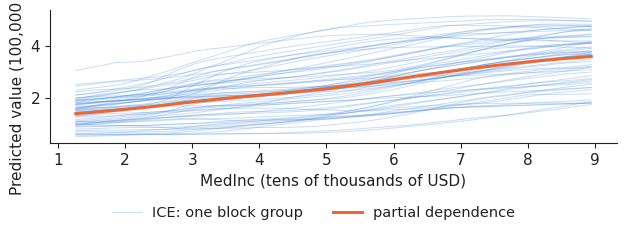

In [5]:
cnet = train_mlp(SEED, CZ[k_tr], cy[k_tr], CZ[k_va], cy[k_va], task='reg', epochs=200, patience=20, lr=2e-3); cf = logit_fn(cnet)
grid = np.linspace(np.percentile(ca.MedInc, 2), np.percentile(ca.MedInc, 98), 40); gz = (grid - cmu['MedInc']) / csd['MedInc']
rg = np.random.default_rng(SEED); rows = CZ[k_te][rg.choice(len(k_te), 60, replace=False)]; prow = CZ[k_te][rg.choice(len(k_te), 1000, replace=False)]
def ice(R):
    out = np.zeros((len(R), len(gz)))
    for g_, z in enumerate(gz):
        Xg = R.copy(); Xg[:, 0] = z; out[:, g_] = cf(Xg)
    return out
I = ice(rows); PD = ice(prow).mean(0); fig, ax = plt.subplots(figsize=(6.4, 2.4))
for i, row in enumerate(I): ax.plot(grid, row, color=PAL['data'], alpha=0.25, lw=0.7, label='ICE: one block group' if i == 0 else None)
ax.plot(grid, PD, color=PAL['model'], lw=2.2, label='partial dependence'); ax.set_xlabel('MedInc (tens of thousands of USD)'); ax.set_ylabel('Predicted value (100,000 USD)')
legend_bottom(fig, ncol=2); fig.tight_layout(rect=(0, 0.12, 1, 1))
fig.savefig('pdp_ice.png', dpi=200, transparent=True, bbox_inches='tight'); plt.show()